# Feature Analysis

Second-stage exploratory data analysis for the Hit Song Prediction project.

## 1. Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
final_df = pd.read_csv("../data/final_dataset.csv")
display(final_df.head())
print("Dataset shape:", final_df.shape)

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,hit
0,Perfidia Cha Cha,['Cal Tjader'],0.858,0.449,-16.531,0.0658,0.77400,0.062500,0.1130,0.890,127.066,0
1,Gir Kanıma,['Harun Kolçak'],0.759,0.714,-9.449,0.0564,0.00163,0.000012,0.0173,0.492,119.775,0
2,It's Over Now,['112'],0.660,0.710,-4.541,0.0409,0.01060,0.000007,0.0736,0.233,97.988,1
3,The Pusher,['Blind Melon'],0.438,0.576,-8.727,0.0320,0.03020,0.000011,0.0988,0.742,165.277,0
4,Toys In The Attic,['Aerosmith'],0.219,0.928,-9.997,0.0697,0.00100,0.000002,0.3410,0.446,197.462,0


Dataset shape: (10000, 12)


## 2. Feature Analysis

In [2]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

### 2.1 Feature Distributions

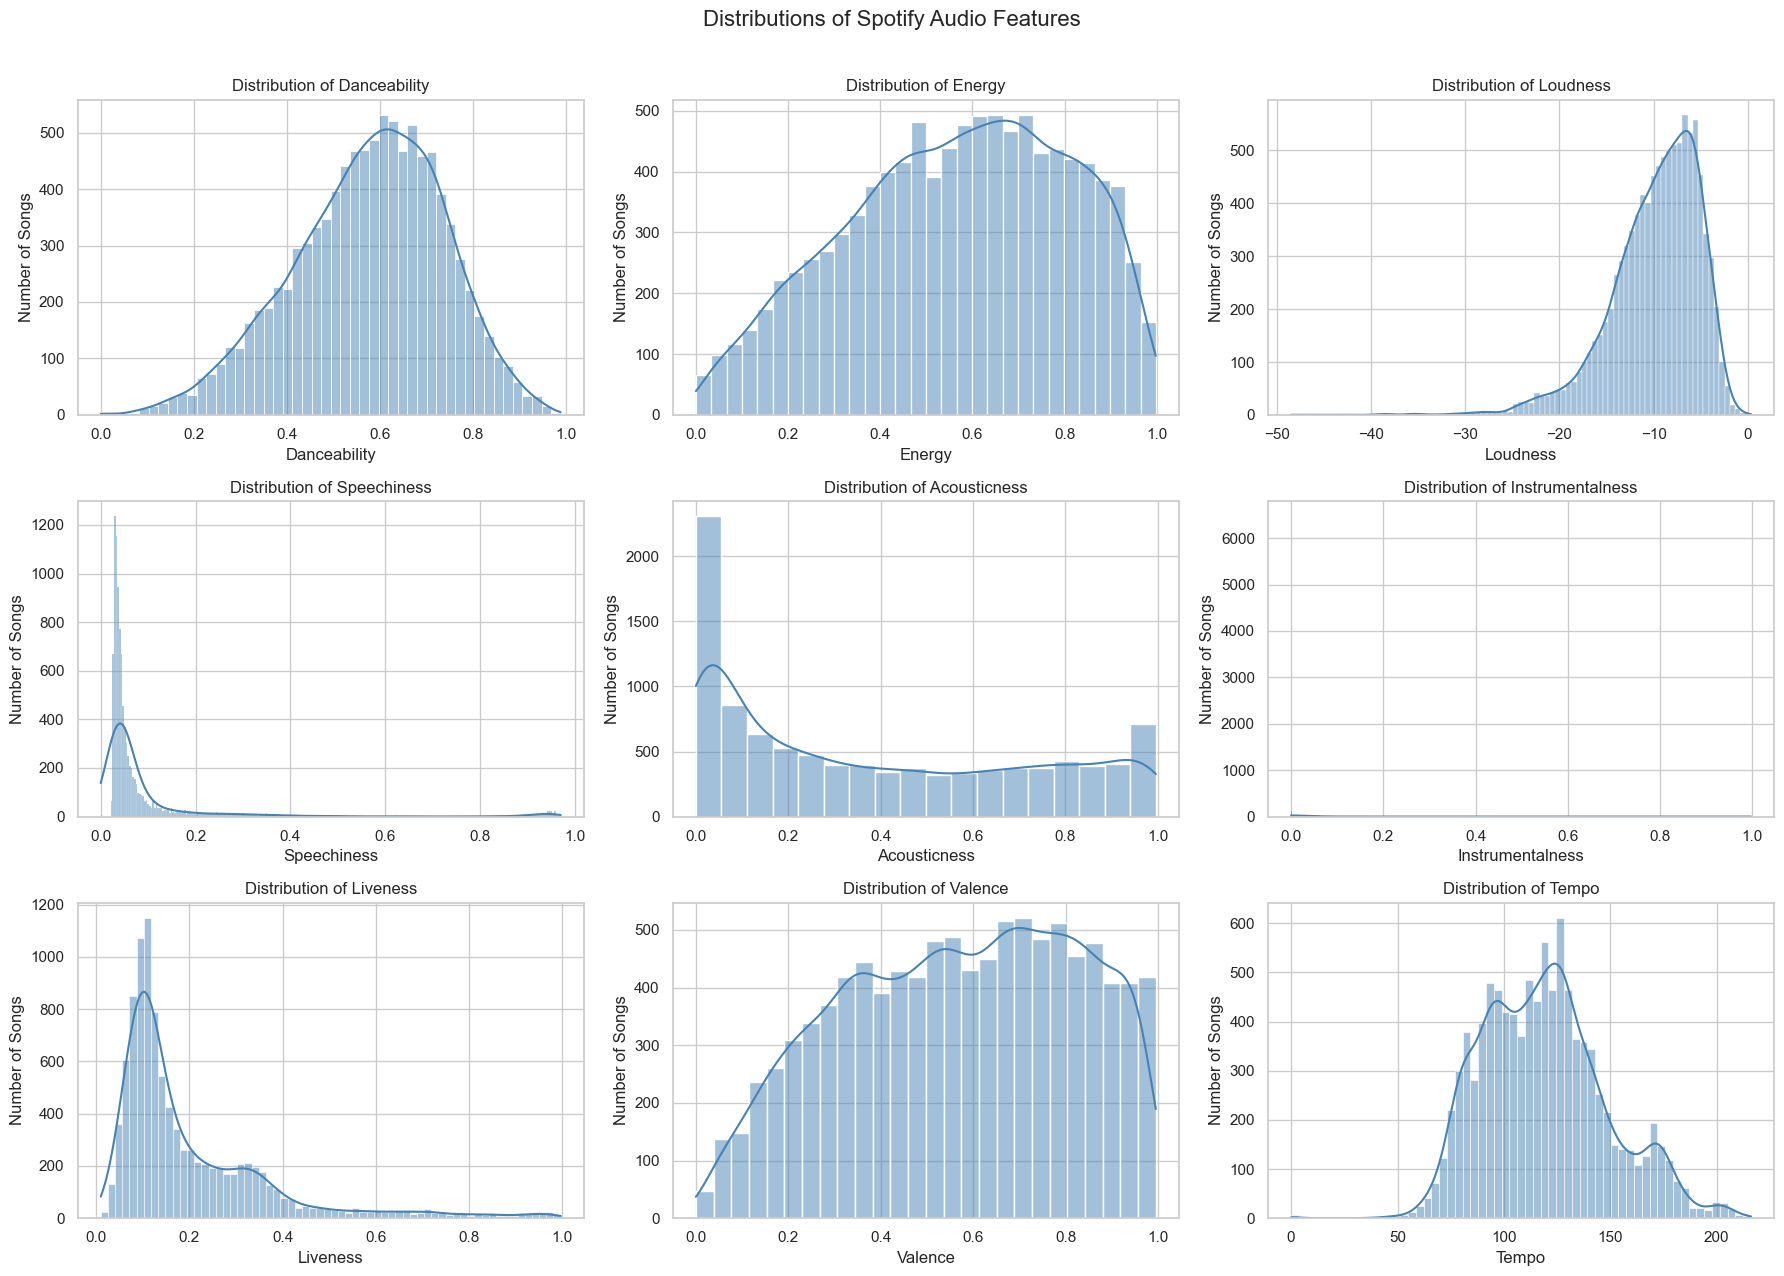

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
axes = axes.ravel()

for ax, feature in zip(axes, audio_features):
    sns.histplot(data=final_df, x=feature, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {feature.replace('_', ' ').title()}")
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Number of Songs")

fig.suptitle("Distributions of Spotify Audio Features", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 2.2 HIT versus NON-HIT Comparison

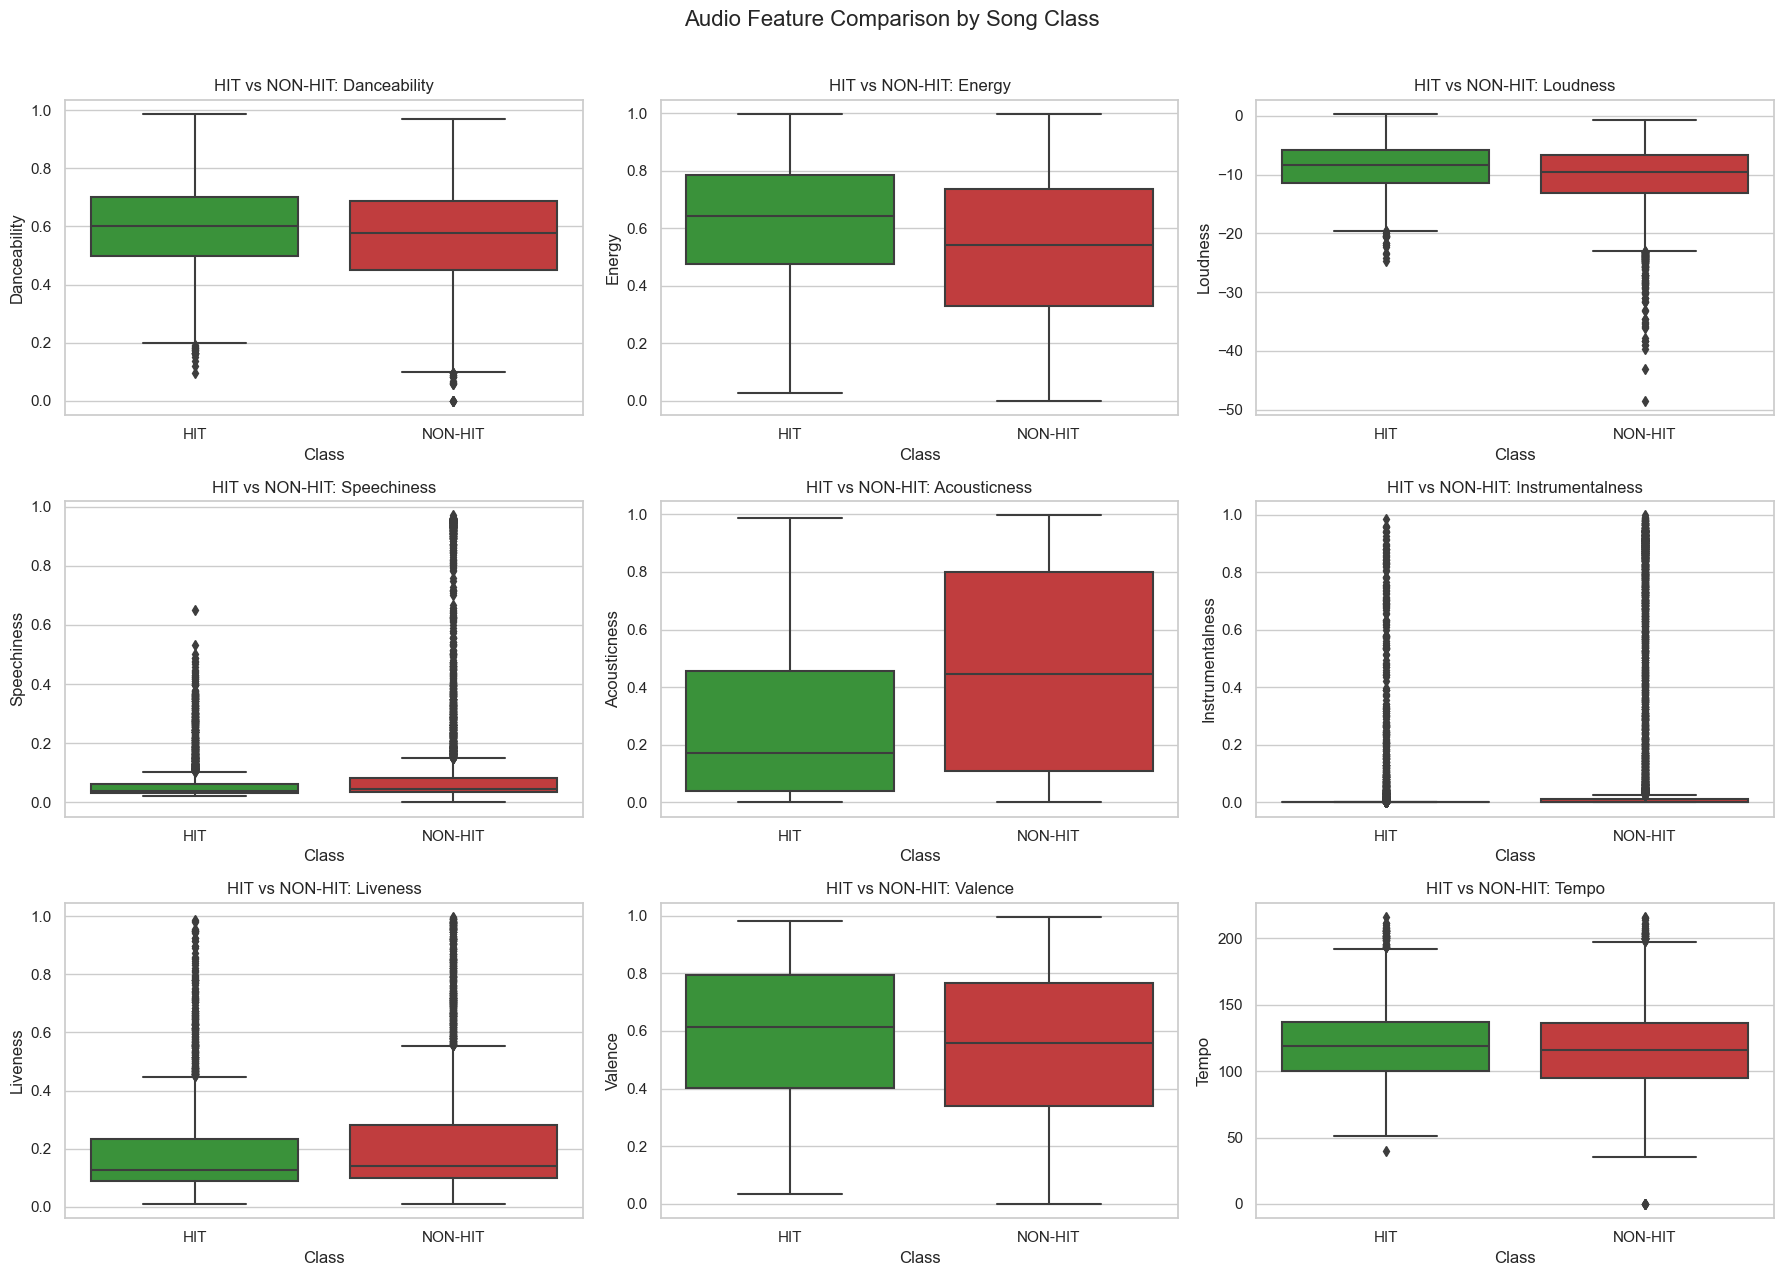

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
axes = axes.ravel()

for ax, feature in zip(axes, audio_features):
    sns.boxplot(
        data=final_df,
        x=final_df["hit"].map({1: "HIT", 0: "NON-HIT"}),
        y=feature,
        order=["HIT", "NON-HIT"],
        palette=["#2ca02c", "#d62728"],
        ax=ax,
    )
    ax.set_title(f"HIT vs NON-HIT: {feature.replace('_', ' ').title()}")
    ax.set_xlabel("Class")
    ax.set_ylabel(feature.replace("_", " ").title())

fig.suptitle("Audio Feature Comparison by Song Class", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 2.3 Correlation Heatmap

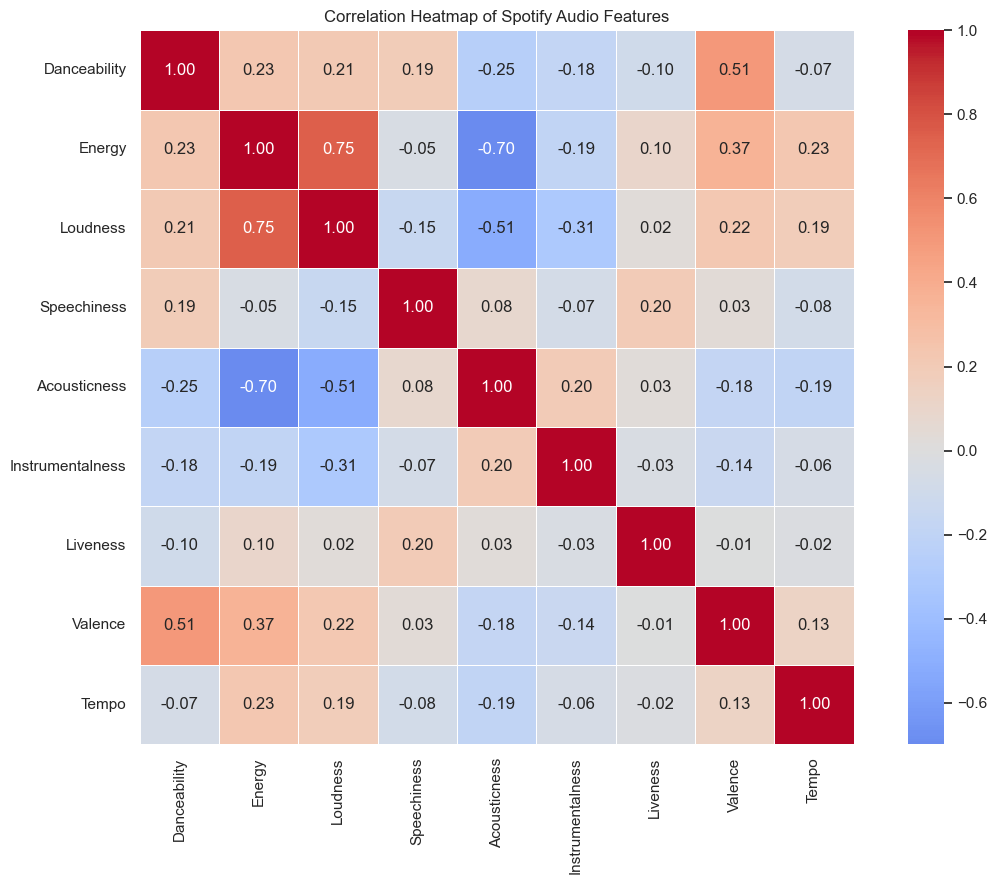

In [5]:
feature_correlation = final_df[audio_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    feature_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    xticklabels=[feature.replace("_", " ").title() for feature in audio_features],
    yticklabels=[feature.replace("_", " ").title() for feature in audio_features],
)
plt.title("Correlation Heatmap of Spotify Audio Features")
plt.tight_layout()
plt.show()

### 2.4 Mean Feature Comparison

In [6]:
hit_means = final_df.loc[final_df["hit"] == 1, audio_features].mean()
non_hit_means = final_df.loc[final_df["hit"] == 0, audio_features].mean()

mean_comparison = pd.DataFrame({
    "feature": audio_features,
    "HIT mean": [hit_means[feature] for feature in audio_features],
    "NON-HIT mean": [non_hit_means[feature] for feature in audio_features],
})

display(mean_comparison)

,feature,HIT mean,NON-HIT mean
0,danceability,0.594264,0.562796
1,energy,0.621519,0.531452
2,loudness,-8.803049,-10.480731
3,speechiness,0.064085,0.116720
4,acousticness,0.271475,0.463044
5,instrumentalness,0.027615,0.118076
6,liveness,0.181650,0.217119
7,valence,0.595192,0.549021
8,tempo,120.806851,117.527343
